<a href="https://colab.research.google.com/github/Tashifur-Rahman/netflix-content-analysis/blob/main/Netflix_content_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid",palette="Set2")
plt.rcParams["figure.figsize"]=(10,6)

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("shivamb/netflix-shows")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'netflix-shows' dataset.
Path to dataset files: /kaggle/input/netflix-shows


In [5]:
df=pd.read_csv("/kaggle/input/netflix-shows/netflix_titles.csv")

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [7]:
df.head(5)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [8]:
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df_clean=df.copy()
#remove extra whitespaces
df_clean.columns=df_clean.columns.str.strip()
text_columns=df_clean.select_dtypes(include=['object','string']).columns
for col in text_columns:
  df_clean[col]=(df_clean[col].str.strip().astype('string').replace("",pd.NA))
print(df_clean.isnull().sum().to_frame("Missing count"))

              Missing count
show_id                   0
type                      0
title                     0
director               2634
cast                    825
country                 831
date_added               10
release_year              0
rating                    4
duration                  3
listed_in                 0
description               0


In [11]:
#rows with missing ratings
print(df_clean[df_clean['rating'].isna()])

     show_id     type                                              title  \
5989   s5990    Movie  13TH: A Conversation with Oprah Winfrey & Ava ...   
6827   s6828  TV Show                  Gargantia on the Verdurous Planet   
7312   s7313  TV Show                                       Little Lunch   
7537   s7538    Movie                               My Honor Was Loyalty   

             director                                               cast  \
5989             <NA>                        Oprah Winfrey, Ava DuVernay   
6827             <NA>  Kaito Ishikawa, Hisako Kanemoto, Ai Kayano, Ka...   
7312             <NA>  Flynn Curry, Olivia Deeble, Madison Lu, Oisín ...   
7537  Alessandro Pepe  Leone Frisa, Paolo Vaccarino, Francesco Miglio...   

        country        date_added  release_year rating  duration  \
5989       <NA>  January 26, 2017          2017   <NA>    37 min   
6827      Japan  December 1, 2016          2013   <NA>  1 Season   
7312  Australia  February 1, 2018 

In [12]:
#rows with missing date added
print(df_clean[df_clean['date_added'].isna()])

     show_id     type                                        title director  \
6066   s6067  TV Show  A Young Doctor's Notebook and Other Stories     <NA>   
6174   s6175  TV Show              Anthony Bourdain: Parts Unknown     <NA>   
6795   s6796  TV Show                                      Frasier     <NA>   
6806   s6807  TV Show                                      Friends     <NA>   
6901   s6902  TV Show                              Gunslinger Girl     <NA>   
7196   s7197  TV Show                                     Kikoriki     <NA>   
7254   s7255  TV Show                          La Familia P. Luche     <NA>   
7406   s7407  TV Show                                        Maron     <NA>   
7847   s7848  TV Show                                 Red vs. Blue     <NA>   
8182   s8183  TV Show                 The Adventures of Figaro Pho     <NA>   

                                                   cast         country  \
6066  Daniel Radcliffe, Jon Hamm, Adam Godley, Chris...

In [13]:
#Missing report
missing_report=pd.DataFrame({
    'Missing':df_clean.isnull().sum(),
    'Missing %':(df_clean.isnull().sum()/len(df_clean)*100).round(2)
})
print("Missing Report:\n",missing_report)

Missing Report:
               Missing  Missing %
show_id             0       0.00
type                0       0.00
title               0       0.00
director         2634      29.91
cast              825       9.37
country           831       9.44
date_added         10       0.11
release_year        0       0.00
rating              4       0.05
duration            3       0.03
listed_in           0       0.00
description         0       0.00


In [14]:
import datetime
df_clean['date_added']=pd.to_datetime(
    df_clean['date_added'],
    format='mixed',
    errors='coerce'
)
print(df_clean[["title","date_added"]].head(5))

                   title date_added
0   Dick Johnson Is Dead 2021-09-25
1          Blood & Water 2021-09-24
2              Ganglands 2021-09-24
3  Jailbirds New Orleans 2021-09-24
4           Kota Factory 2021-09-24


In [15]:
#extract numeric values and units from duration
duration_parts=df_clean["duration"].str.extract(
    r"^\s*(\d+)\s*(min|season|seasons|episodes)\s*$",
    flags=2
)
df_clean["duration_value"]=pd.to_numeric(
    duration_parts[0],errors="coerce"
)
df_clean["duration_unit"]=duration_parts[1].str.lower()

df_clean["movie_duration_min"]=(
    df_clean["duration_value"].where(
        (df_clean["type"]=="Movie")&(df_clean["duration_unit"]=="min")
    )
)

In [16]:
#seperate multiple countries by ,

country_df = df_clean[
    ["show_id", "country"]
].dropna(subset=["country"]).copy()

country_df["country"] = country_df["country"].str.split(",")

country_df = country_df.explode("country")

country_df["country"] = country_df["country"].str.strip()

country_df = country_df[
    country_df["country"].ne("")
]

print("Country-level records:")
display(country_df.head(10))


Country-level records:


,show_id,country
0,s1,United States
1,s2,South Africa
4,s5,India
7,s8,United States
7,s8,Ghana
7,s8,Burkina Faso
7,s8,United Kingdom
7,s8,Germany
7,s8,Ethiopia
8,s9,United Kingdom


In [17]:

display(country_df[country_df["show_id"] == "s615"])


,show_id,country
614,s615,United States
614,s615,New Zealand


# **Top 10 Countries**

In [18]:
country_counts=country_df["country"].value_counts()
print("Country-level counts:")
display(country_counts)

Country-level counts:


,count
country,
United States,3690
India,1046
United Kingdom,806
Canada,445
France,393
...,...
Sudan,1
Panama,1
Uganda,1


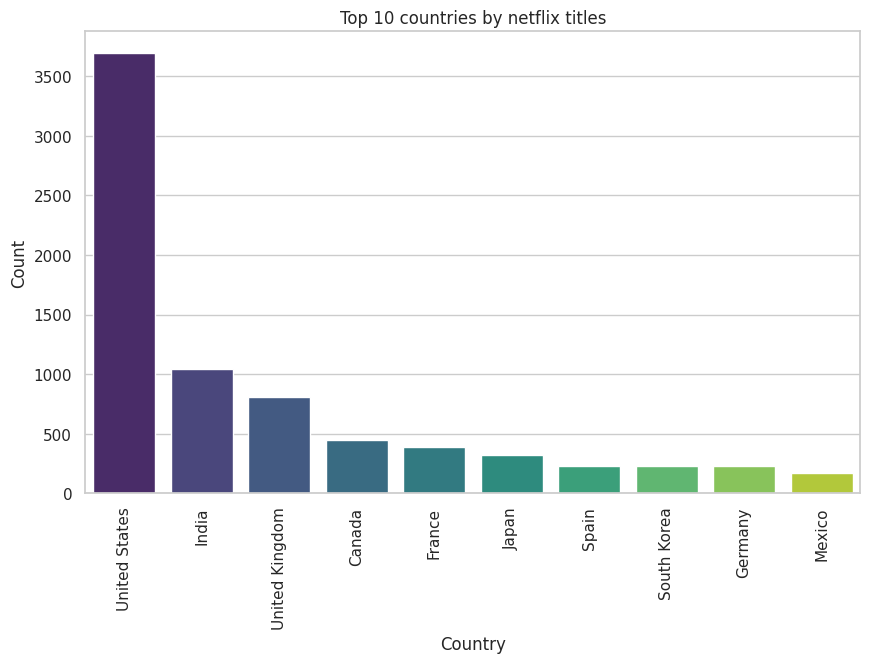

In [19]:
top10_countries=country_counts.head(10)
plt.figure(figsize=(10,6))
sns.barplot(
    x=top10_countries.index,
    y=top10_countries.values,
    palette="viridis"
)
plt.title("Top 10 countries by netflix titles")
plt.xlabel("Country")
plt.ylabel("Count")
plt.xticks(rotation=90)
plt.show()

([<matplotlib.patches.Wedge at 0x7c6ae91cda90>,
 [Text(0.040237852942167515, 1.0992638060040931, 'United States'),
  Text(-1.0288169285712936, -0.3892759014954947, 'India'),
  Text(-0.46759551603011706, -0.995667832858192, 'United Kingdom'),
  Text(0.0890866217871244, -1.0963865987043795, 'Canada'),
  Text(0.45805371721212396, -1.0000933917130719, 'France'),
  Text(0.7295407829286832, -0.823268028070934, 'Japan'),
  Text(0.8971742697885136, -0.6364576416616016, 'Spain'),
  Text(1.0023669654372425, -0.45305680284058675, 'South Korea'),
  Text(1.069894742619912, -0.2555880273296707, 'Germany'),
  Text(1.0972857011005646, -0.0772275220387308, 'Mexico')],
 [Text(0.021947919786636825, 0.5995984396385962, '48.8%'),
  Text(-0.5611728701297964, -0.21233230990663343, '13.8%'),
  Text(-0.25505209965279113, -0.5430915451953774, '10.7%'),
  Text(0.048592702792976936, -0.5980290538387524, '5.9%'),
  Text(0.24984748211570396, -0.5455054863889482, '5.2%'),
  Text(0.39793133614291804, -0.4490552880386

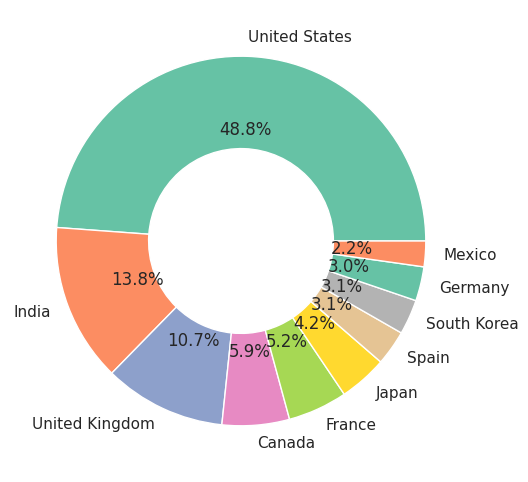

In [20]:
#donut chart
plt.figure(figsize=(6,6))
plt.pie(
    top10_countries.values,
    labels=top10_countries.index,
    wedgeprops=dict(width=0.5),
    autopct="%1.1f%%" #for percent label
)


Yearly Addition

In [21]:
df_clean["added_year"]=df_clean["date_added"].dt.year
yearly_additions=(
    df_clean["added_year"].value_counts().sort_index()
)
display(yearly_additions)

,count
added_year,
2008.0,2
2009.0,2
2010.0,1
2011.0,13
2012.0,3
2013.0,11
2014.0,24
2015.0,82
2016.0,429


# **Yearly Distribution of Content Added to Netflix**

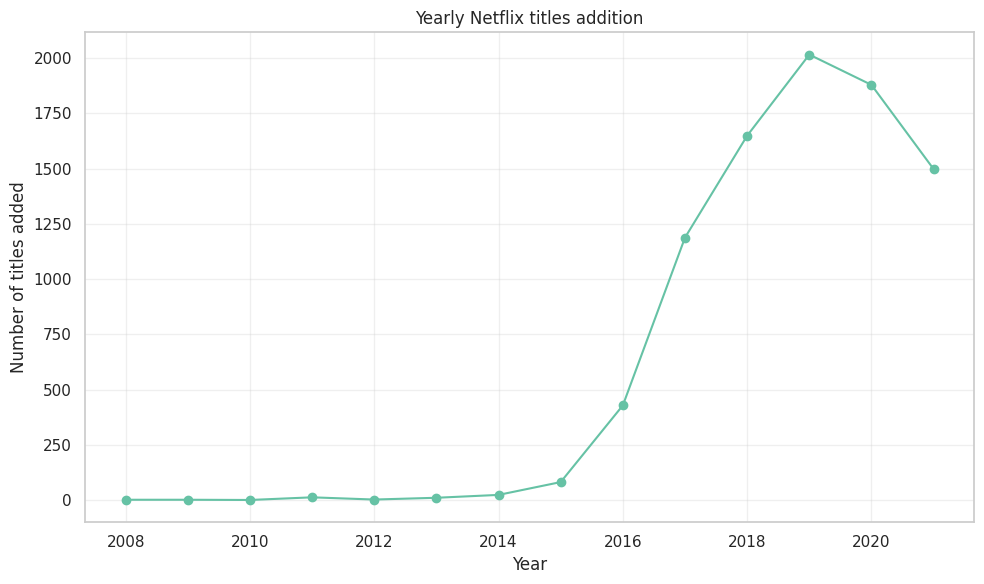

In [22]:
plt.figure(figsize=(10,6))
plt.plot(
    yearly_additions.index,
    yearly_additions.values,
    marker="o"
)
plt.title("Yearly Netflix titles addition")
plt.xlabel("Year")
plt.ylabel("Number of titles added")
plt.tight_layout()
plt.grid(alpha=0.3)
plt.show()

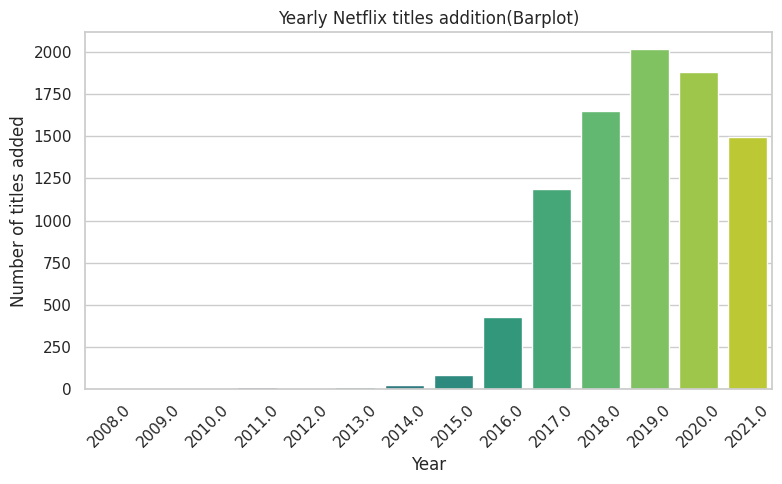

In [23]:
plt.figure(figsize=(8,5))
sns.barplot(
    x=yearly_additions.index,
    y=yearly_additions.values,
    palette="viridis",

)
plt.title("Yearly Netflix titles addition(Barplot)")
plt.xlabel("Year")
plt.ylabel("Number of titles added")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Content Type

In [24]:
contents_count=df_clean["type"].value_counts()
print(contents_count)

type
Movie      6131
TV Show    2676
Name: count, dtype: Int64


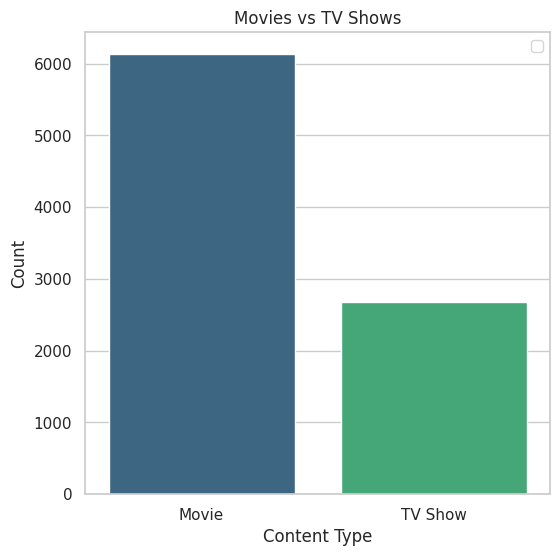

In [25]:
plt.figure(figsize=(6,6))
sns.barplot(
    x=contents_count.index,
    y=contents_count.values,
    palette="viridis"

)
plt.title("Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Count")
plt.legend()
plt.show()

# **Rating Distribution**


In [26]:
rating_counts=df_clean["rating"].value_counts()
print(rating_counts)

rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: Int64


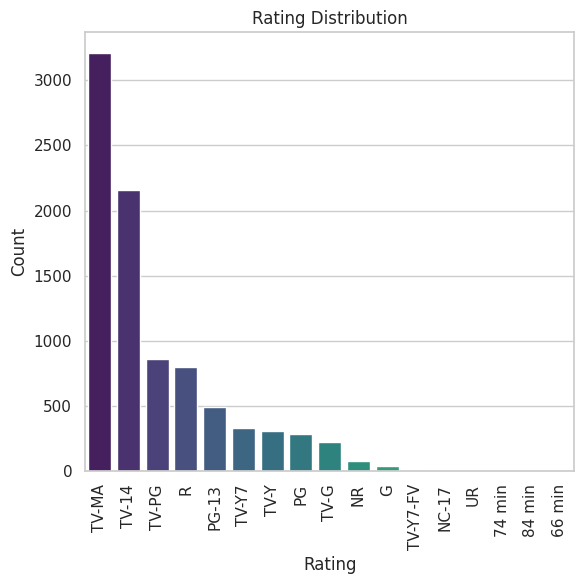

In [27]:
plt.figure(figsize=(6,6))
sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values,
    palette="viridis"
)
plt.title("Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# **Analysis of Top 10 Genres**

In [28]:
genre_df=df_clean[["show_id","listed_in"]].copy()
genre_df["listed_in"]=genre_df["listed_in"].str.split(",")
genre_df=genre_df.explode("listed_in")
genre_df["listed_in"]=genre_df["listed_in"].str.strip()


In [29]:
genre_counts=genre_df["listed_in"].value_counts()
print(genre_counts)

listed_in
International Movies            2752
Dramas                          2427
Comedies                        1674
International TV Shows          1351
Documentaries                    869
Action & Adventure               859
TV Dramas                        763
Independent Movies               756
Children & Family Movies         641
Romantic Movies                  616
TV Comedies                      581
Thrillers                        577
Crime TV Shows                   470
Kids' TV                         451
Docuseries                       395
Music & Musicals                 375
Romantic TV Shows                370
Horror Movies                    357
Stand-Up Comedy                  343
Reality TV                       255
British TV Shows                 253
Sci-Fi & Fantasy                 243
Sports Movies                    219
Anime Series                     176
Spanish-Language TV Shows        174
TV Action & Adventure            168
Korean TV Shows             

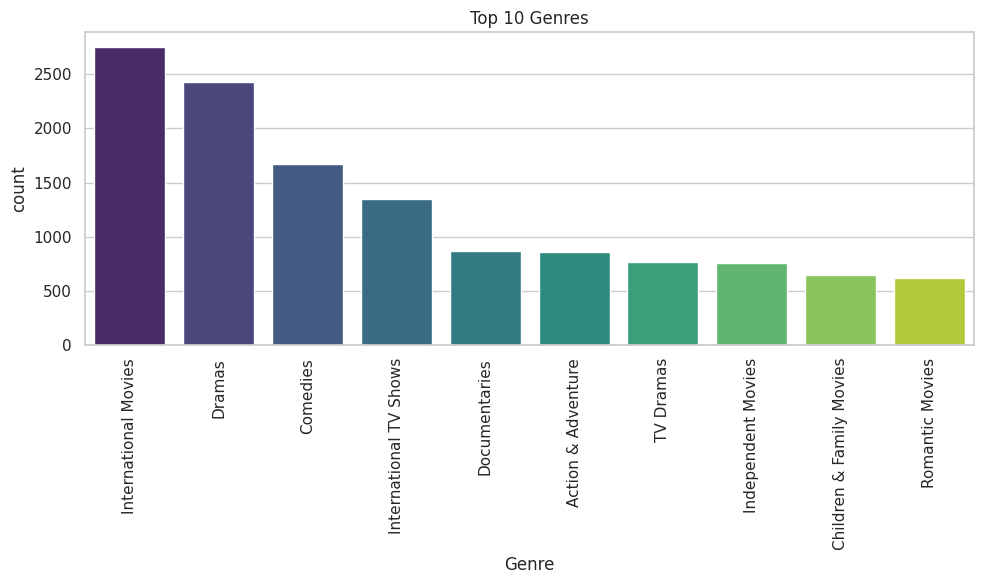

In [30]:
top10_genres=genre_counts.head(10)
plt.figure(figsize=(10,6))
sns.barplot(
    x=top10_genres.index,
    y=top10_genres.values,
    palette="viridis"
)
plt.title("Top 10 Genres")
plt.xlabel("Genre")
plt.ylabel("count")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

([<matplotlib.patches.Wedge at 0x7c6ae9b0ccd0>,
 [Text(0.8551000573396658, 0.6919565679561834, 'International Movies'),
  Text(-0.4180610143000726, 1.0174600671880911, 'Dramas'),
  Text(-1.0846753468143508, 0.182973746786712, 'Comedies'),
  Text(-0.9196836847483673, -0.6034748710656195, 'International TV Shows'),
  Text(-0.46980347471111183, -0.9946279179418633, 'Documentaries'),
  Text(-0.015499590295301182, -1.0998907958068738, 'Action & Adventure'),
  Text(0.4150410708365304, -1.0186956903407742, 'TV Dramas'),
  Text(0.7597307912285687, -0.7954930074232037, 'Independent Movies'),
  Text(0.9841729970223868, -0.4913283137902529, 'Children & Family Movies'),
  Text(1.087269985238621, -0.16686515274079636, 'Romantic Movies')],
 [Text(0.4664182130943631, 0.3774308552488273, '21.7%'),
  Text(-0.22803328052731228, 0.5549782184662314, '19.1%'),
  Text(-0.5916410982623731, 0.09980386188366107, '13.2%'),
  Text(-0.5016456462263821, -0.32916811149033787, '10.6%'),
  Text(-0.2562564407515155, -

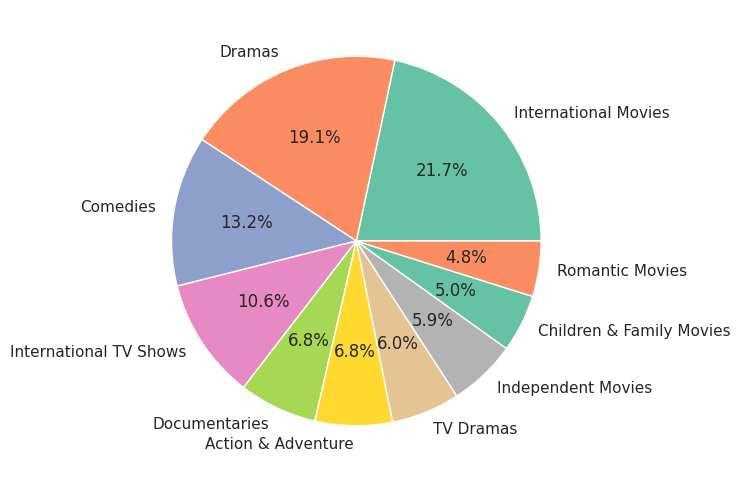

In [31]:
#Donut chart for Top 10 Genres
plt.figure(figsize=(6,6))
plt.pie(
    top10_genres.values,
    labels=top10_genres.index,
    autopct="%1.1f%%"
)

# **Movie Duration Distribution**




In [32]:
movie_runtime=df_clean["movie_duration_min"].dropna()
print(movie_runtime)

0        90
6        91
7       125
9       104
12      127
       ... 
8801     96
8802    158
8804     88
8805     88
8806    111
Name: movie_duration_min, Length: 6128, dtype: Int64


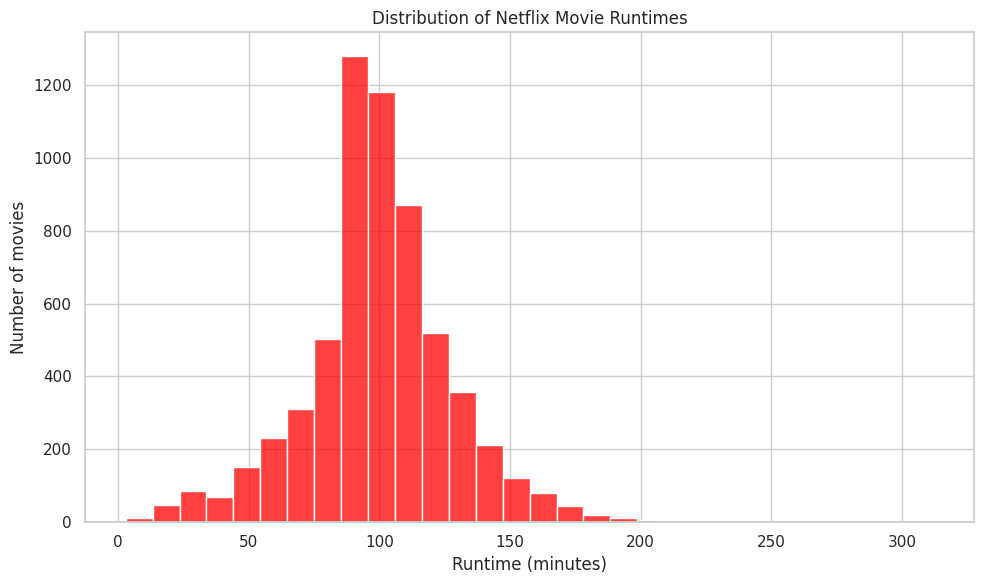

In [33]:
plt.figure(figsize=(10,6))
sns.histplot(
    data=movie_runtime,
    bins=30,
    color="red"
)
plt.title("Distribution of Netflix Movie Runtimes")
plt.xlabel("Runtime (minutes)")
plt.ylabel("Number of movies")
plt.tight_layout()
plt.show()


## **Distribution of TV Shows based on Number of Seasons**

In [55]:
df_clean["tv_seasons"]=df_clean["duration_value"].where(
    (df_clean["type"]=="TV Show")).copy()


In [56]:
tv_df=df_clean[df_clean["type"]=="TV Show"]
season_counts=tv_df["tv_seasons"].dropna()
print(season_counts)

1       2
2       1
3       1
4       2
5       1
       ..
8795    2
8796    2
8797    3
8800    1
8803    2
Name: tv_seasons, Length: 2676, dtype: Int64


In [59]:
season_counts=season_counts.value_counts().sort_index(ascending=False)
print(season_counts)

count
1793    1
425     1
199     1
95      1
65      1
33      1
23      1
17      1
9       1
7       1
3       1
2       3
1       1
Name: count, dtype: Int64


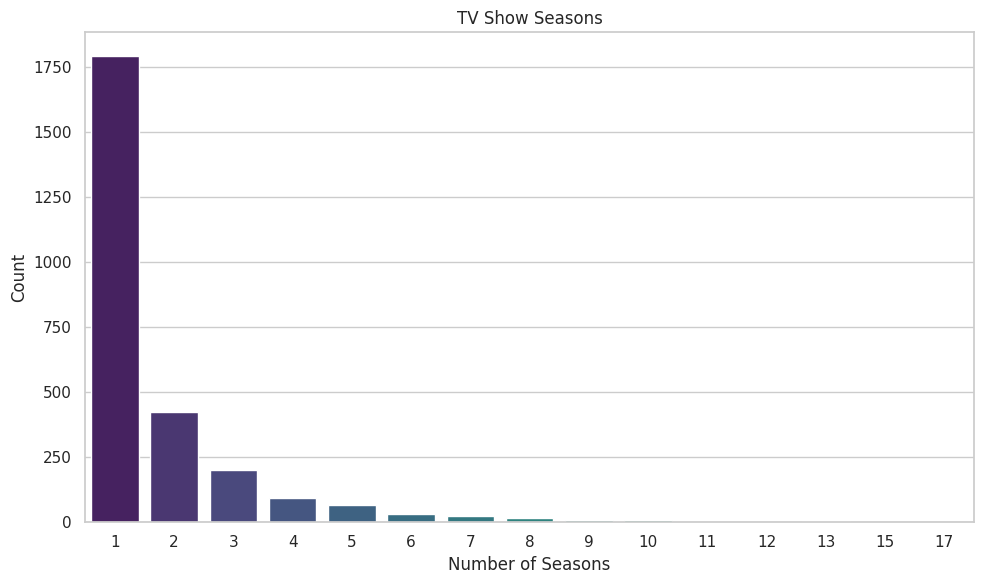

In [58]:
plt.figure(figsize=(10,6))
sns.barplot(
    x=season_counts.index,
    y=season_counts.values,
    palette="viridis"
)
plt.title("TV Show Seasons")
plt.xlabel("Number of Seasons")
plt.ylabel("Count")
plt.tight_layout()
plt.show()